In [66]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [67]:
# Load all datasets from the results directory
# Pattern: "scoring/{anonymization_method}/{embedding_method}/{aggregation_method}/scores.parquet"
SCORES_PATH = Path("../../results/scoring")

_scores = []
for anonymization_method in SCORES_PATH.iterdir():
    if not anonymization_method.is_dir():
        continue
    for embedding_method in anonymization_method.iterdir():
        if not embedding_method.is_dir():
            continue
        for aggregation_method in embedding_method.iterdir():
            if not aggregation_method.is_dir():
                continue
            _score = pd.read_parquet(str(aggregation_method / "scores.parquet"))
            for _, _s in _score.iterrows():
                _scores.append(
                    {
                        "key": f"{anonymization_method.name}/{embedding_method.name}/{aggregation_method.name}",
                        "anonymization_method": anonymization_method.name,
                        "embedding_method": embedding_method.name,
                        "aggregation_method": aggregation_method.name,
                        "accuracy": _s["accuracy"],
                    }
                )
scores = pd.DataFrame(_scores)
scores

,key,anonymization_method,embedding_method,aggregation_method,accuracy
0,none/arcface/clustering_median_d08_min3,none,arcface,clustering_median_d08_min3,0.516194
1,none/arcface/clustering_median_d08_min3,none,arcface,clustering_median_d08_min3,0.548387
2,none/arcface/clustering_median_d08_min3,none,arcface,clustering_median_d08_min3,0.542446
3,none/arcface/pooling_mean,none,arcface,pooling_mean,0.565217
4,none/arcface/pooling_mean,none,arcface,pooling_mean,0.606419
5,none/arcface/pooling_mean,none,arcface,pooling_mean,0.556377
6,none/arcface/clustering_median_d1_min3,none,arcface,clustering_median_d1_min3,0.605982
7,none/arcface/clustering_median_d1_min3,none,arcface,clustering_median_d1_min3,0.635452
8,none/arcface/clustering_median_d1_min3,none,arcface,clustering_median_d1_min3,0.627273
9,none/arcface/clustering_mean_d1_min3,none,arcface,clustering_mean_d1_min3,0.561769


<Axes: xlabel='accuracy', ylabel='key'>

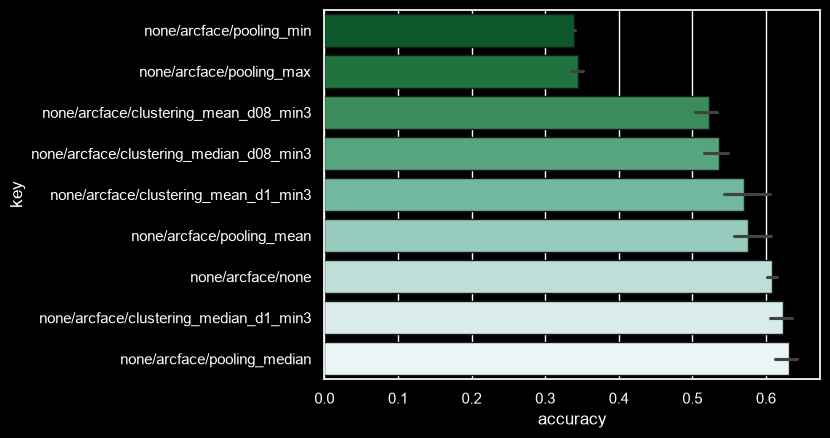

In [71]:
# Create a graph showing the accuracy_mean and accuracy_std (eror bars) for each combination of anonymization_method, embedding_method, and aggregation_method.

_order = (
    scores.groupby("key")["accuracy"]
    .aggregate(np.median)
    .reset_index()
    .sort_values("accuracy")
)
_palette = sns.color_palette("BuGn_r", n_colors=len(scores["key"].unique()))
sns.barplot(
    data=scores,
    y="key",
    x="accuracy",
    orient="h",
    order=_order["key"],
    hue_order=_order["key"],
    hue="key",
    palette=_palette,
    ec="k",
    legend=False,
)